<a href="https://colab.research.google.com/github/smg063244/4NI25CS202_DAV_LAB/blob/main/4NI25CS202_EXP_11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Lab 11: Hierarchical Clustering:Building dendrogram and applying agglomerative clustering

In [ ]:
import pandas as pd
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

In [ ]:
from google.colab import files
uploaded=files.upload()

Saving House_Price_dataset.csv to House_Price_dataset (2).csv


Clean data

In [ ]:
# Load dataset and select features
df = pd.read_csv('/content/House_Price_dataset.csv')
df = df[df['purpose'] == 'For Sale']
df = df[['price', 'bedrooms', 'baths', 'Area Size']].dropna()

# Clean data: remove zero values and extreme outliers
df = df[(df['bedrooms'] > 0) & (df['baths'] > 0)]
df = df[df['price'] < df['price'].quantile(0.99)]
df = df[df['Area Size'] < df['Area Size'].quantile(0.99)]

In [ ]:
df=df.sample(n=100,random_state=42).reset_index(drop=True)

In [ ]:
X=df[['price','bedrooms','Area Size']]
X_scaled=StandardScaler().fit_transform(X)

Build and plot dendrogram

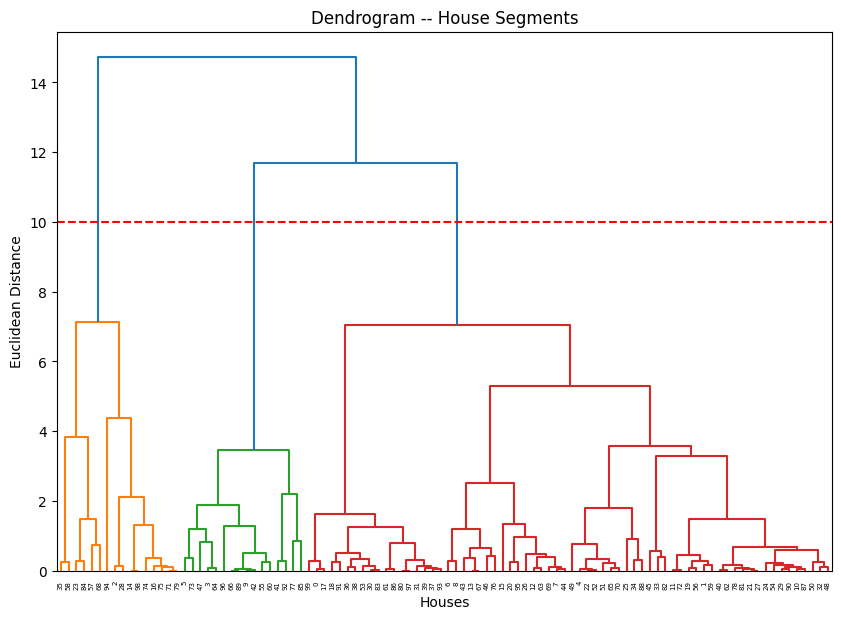

In [ ]:
linked=linkage(X_scaled,method='ward')
plt.figure(figsize=(10,7))
dendrogram(linked)
plt.title('Dendrogram -- House Segments')
plt.xlabel('Houses')
plt.ylabel('Euclidean Distance')
plt.axhline(y=10,color='red',linestyle='--')
plt.show()

In [ ]:
hc=AgglomerativeClustering(n_clusters=3,linkage='ward')
df['HC_Cluster']=hc.fit_predict(X_scaled)

In [ ]:
print(df["HC_Cluster"].value_counts())
print(df.groupby("HC_Cluster").mean().round(2))

HC_Cluster
1    68
0    16
2    16
Name: count, dtype: int64
                  price  bedrooms  baths  Area Size
HC_Cluster                                         
0           55650000.00      5.44   5.81       1.21
1           11721617.65      2.97   3.12       5.40
2           26750000.00      4.94   4.94      10.93


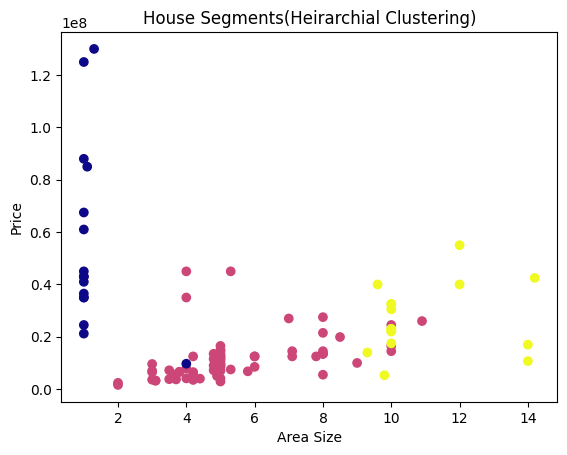

In [ ]:
plt.scatter(df["Area Size"], df["price"], c=df["HC_Cluster"],cmap='plasma')
plt.xlabel("Area Size")
plt.ylabel("Price")
plt.title("House Segments(Heirarchial Clustering)")
plt.show()